# Vibe Quest 4

In [4]:
# @title Investigación 1: El Efecto del Outlier (Con Vectores de Soporte) { run: "auto" }
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import make_blobs
from ipywidgets import interact, FloatSlider

def plot_svm_outlier_vis(C_param, outlier_pos):
    # 1. Datos
    X, y = make_blobs(n_samples=50, centers=[(-2, -2), (2, 2)], cluster_std=0.8, random_state=42)
    outlier_X = np.array([[-1, outlier_pos]])
    outlier_y = np.array([1])
    X_combined = np.vstack([X, outlier_X])
    y_combined = np.hstack([y, outlier_y])

    # 2. Modelo
    clf = SVC(kernel='linear', C=C_param)
    clf.fit(X_combined, y_combined)

    # 3. Visualización
    plt.figure(figsize=(10, 6))

    # Puntos normales
    plt.scatter(X_combined[:, 0], X_combined[:, 1], c=y_combined, s=50, cmap='viridis', edgecolors='k')
    # Resaltar Outlier
    plt.scatter(outlier_X[:, 0], outlier_X[:, 1], c='red', s=100, marker='x', label='Outlier (Ruido)')

    # --- LO NUEVO: VECTORES DE SOPORTE ---
    # Dibujamos círculos alrededor de los puntos que el SVM usa para definir la linea
    plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=250,
                linewidth=1.5, facecolors='none', edgecolors='k', label='Vectores de Soporte')

    # Frontera
    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    xx = np.linspace(xlim[0], xlim[1], 30)
    yy = np.linspace(ylim[0], ylim[1], 30)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = clf.decision_function(xy).reshape(XX.shape)

    # Lineas de margen
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

    plt.title(f"C={C_param}: Observa qué puntos tienen el círculo negro.\nEsos son los únicos que importan.", fontsize=12)
    plt.legend(loc='lower right')
    plt.show()

interact(plot_svm_outlier_vis,
         C_param=FloatSlider(value=1.0, min=0.01, max=100.0, step=0.1, description='C (Rigidez):'),
         outlier_pos=FloatSlider(value=0, min=-3, max=3, step=0.1, description='Pos Outlier:'));

interactive(children=(FloatSlider(value=1.0, description='C (Rigidez):', min=0.01), FloatSlider(value=0.0, des…

In [9]:
# @title Investigación 2: Desbalance (Con Vectores de Soporte) { run: "auto" }
from sklearn.datasets import make_classification
from ipywidgets import IntSlider

def plot_svm_imbalance_vis(weight_minority, n_minority_samples):
    # 1. Datos Desbalanceados
    X, y = make_classification(n_samples=200, n_features=2, n_redundant=0, n_informative=2,
                               n_clusters_per_class=1, weights=[0.9, 0.1], flip_y=0, random_state=1)

    mask_majority = y == 0
    mask_minority = y == 1
    X_maj = X[mask_majority]
    X_min = X[mask_minority][:n_minority_samples]

    X_imb = np.vstack([X_maj, X_min])
    y_imb = np.hstack([np.zeros(len(X_maj)), np.ones(len(X_min))])

    # 2. Modelo
    weights = {0: 1.0, 1: weight_minority}
    clf = SVC(kernel='linear', class_weight=weights, C=1.0)
    clf.fit(X_imb, y_imb)

    # 3. Visualización
    plt.figure(figsize=(10, 6))
    plt.scatter(X_maj[:, 0], X_maj[:, 1], c='purple', s=50, alpha=0.6, label='Clase Mayoritaria')
    plt.scatter(X_min[:, 0], X_min[:, 1], c='yellow', s=100, edgecolors='k', label='Clase Minoritaria')

    # --- LO NUEVO: VECTORES DE SOPORTE ---
    plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=250,
                linewidth=1.5, facecolors='none', edgecolors='k', label='Vectores de Soporte')

    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    xx = np.linspace(xlim[0], xlim[1], 30)
    yy = np.linspace(ylim[0], ylim[1], 30)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = clf.decision_function(xy).reshape(XX.shape)

    ax.contour(XX, YY, Z, colors='k', levels=[0], alpha=0.8, linestyles=['-'])
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 1], alpha=0.3, linestyles=['--'])

    plt.title(f"Peso Minoría: {weight_minority} | Observa cuántos círculos hay en la clase amarilla.", fontsize=12)
    plt.legend()
    plt.show()

interact(plot_svm_imbalance_vis,
         weight_minority=FloatSlider(value=1.0, min=1.0, max=10.0, step=0.5, description='Peso Min:'),
         n_minority_samples=IntSlider(value=10, min=3, max=20, step=1, description='N Muestras:'));

interactive(children=(FloatSlider(value=1.0, description='Peso Min:', max=10.0, min=1.0, step=0.5), IntSlider(…

In [10]:
# @title Investigación 2.1: El "Estrés" de la Minoría (Con Métricas) { run: "auto" }
from sklearn.datasets import make_classification
from sklearn.svm import SVC
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider

def plot_svm_imbalance_metrics(n_minority_samples, weight_minority):
    # 1. Generar Datos
    X, y = make_classification(n_samples=200, n_features=2, n_redundant=0, n_informative=2,
                               n_clusters_per_class=1, weights=[0.9, 0.1], flip_y=0, random_state=1)

    # Filtrar para controlar el desbalance exacto
    mask_majority = y == 0
    mask_minority = y == 1
    X_maj = X[mask_majority]
    X_min = X[mask_minority][:n_minority_samples] # Reducimos la minoría manualmente

    X_imb = np.vstack([X_maj, X_min])
    y_imb = np.hstack([np.zeros(len(X_maj)), np.ones(len(X_min))])

    # 2. Entrenar SVM
    weights = {0: 1.0, 1: weight_minority}
    clf = SVC(kernel='linear', class_weight=weights, C=1.0)
    clf.fit(X_imb, y_imb)

    # 3. Obtener conteo de Vectores de Soporte
    # clf.n_support_ devuelve un array: [n_SVs_clase0, n_SVs_clase1]
    n_sv_maj = clf.n_support_[0]
    n_sv_min = clf.n_support_[1]

    pct_maj = (n_sv_maj / len(X_maj)) * 100
    pct_min = (n_sv_min / len(X_min)) * 100

    # 4. Visualización
    plt.figure(figsize=(10, 7)) # Un poco más grande para leer el texto

    # Dibujar puntos
    plt.scatter(X_maj[:, 0], X_maj[:, 1], c='purple', s=50, alpha=0.3, label='Mayoría')
    plt.scatter(X_min[:, 0], X_min[:, 1], c='yellow', s=100, edgecolors='k', label='Minoría')

    # Dibujar Círculos en los Vectores de Soporte
    plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=250,
                linewidth=1.5, facecolors='none', edgecolors='k', label='Vectores de Soporte')

    # Frontera
    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    xx = np.linspace(xlim[0], xlim[1], 30)
    yy = np.linspace(ylim[0], ylim[1], 30)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = clf.decision_function(xy).reshape(XX.shape)

    ax.contour(XX, YY, Z, colors='k', levels=[0], alpha=0.8, linestyles=['-'])
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 1], alpha=0.2, linestyles=['--'])

    # Título Informativo
    title_text = (f"Total Muestras Minoría: {len(X_min)}\n"
                  f"SVs Minoría: {n_sv_min} ({pct_min:.1f}% de la clase)\n"
                  f"SVs Mayoría: {n_sv_maj} ({pct_maj:.1f}% de la clase)")

    plt.title(title_text, fontsize=12, fontweight='bold')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.2)
    plt.show()

interact(plot_svm_imbalance_metrics,
         n_minority_samples=IntSlider(value=5, min=3, max=30, step=1, description='Cant. Minoría:'),
         weight_minority=FloatSlider(value=1.0, min=0.5, max=5.0, step=0.5, description='Peso Minoría:'));

interactive(children=(IntSlider(value=5, description='Cant. Minoría:', max=30, min=3), FloatSlider(value=1.0, …

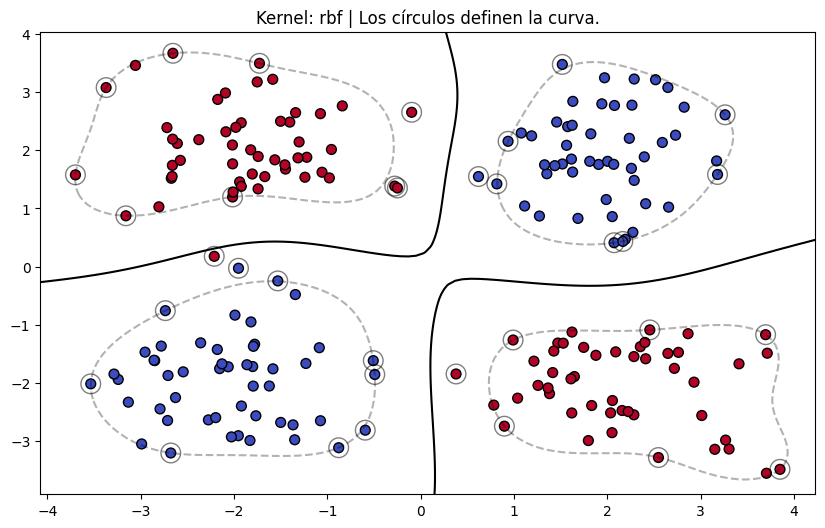

In [7]:
# @title Investigación 3: Multimodal (Con Vectores de Soporte) { run: "auto" }

def plot_svm_multimodal_vis(kernel_type, C_param):
    # 1. Datos XOR
    X, y = make_blobs(n_samples=200, centers=[(2,2), (-2,-2), (2,-2), (-2,2)], cluster_std=0.8, random_state=42)
    y = np.array([0 if (x[0]>0 and x[1]>0) or (x[0]<0 and x[1]<0) else 1 for x in X])

    # 2. Modelo
    clf = SVC(kernel=kernel_type, C=C_param, gamma='auto')
    clf.fit(X, y)

    # 3. Visualización
    plt.figure(figsize=(10, 6))
    plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='coolwarm', edgecolors='k')

    # --- LO NUEVO: VECTORES DE SOPORTE ---
    # En RBF puede haber MUCHOS vectores de soporte si C es bajo
    plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=200,
                linewidth=1.0, facecolors='none', edgecolors='k', alpha=0.5, label='Vectores de Soporte')

    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    xx = np.linspace(xlim[0], xlim[1], 100)
    yy = np.linspace(ylim[0], ylim[1], 100)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T

    Z = clf.decision_function(xy).reshape(XX.shape)

    ax.contour(XX, YY, Z, colors='k', levels=[0], alpha=1, linestyles=['-'])
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 1], alpha=0.3, linestyles=['--'])

    plt.title(f"Kernel: {kernel_type} | Los círculos definen la curva.", fontsize=12)
    plt.show()

interact(plot_svm_multimodal_vis,
         kernel_type=['linear', 'rbf'],
         C_param=FloatSlider(value=1.0, min=0.1, max=10.0, step=0.1, description='Parámetro C:'));